# Falhas em eixo de motor — análise e classificação por vibração

**Objetivo:** classificar o estado de um motor (parado, normal, com peso preso ao eixo — leve ou forte — e com parafuso de
fixação frouxo) a partir de janelas de vibração de 3 eixos medidas por um LSM6DS3 (1,66 kHz) e enviadas por Wi-Fi ao coletor.
Só entram falhas que dá para **provocar ao vivo na bancada**; rolamentos defeituosos ficam de fora.

> **Dados desta versão:** gravações **sintéticas** do simulador (`../simulator`), no mesmo formato do coletor. O motor
> real ainda não existe. O notebook roda igual com dados reais: troque `DATA_DIR` e `SOURCE` na primeira célula de código.
> Resultados sobre dados simulados são **otimistas** (o modelo e o simulador compartilham as mesmas ideias de física);
> o valor aqui é o método, o pipeline e as perguntas certas para quando os dados reais chegarem.

## Decisões de método (e por quê)

| Decisão | Escolha | Justificativa |
|---|---|---|
| **Algoritmo** | **Random Forest** (scikit-learn) sobre features espectrais | Poucos dados *independentes* (poucas sessões), 5 classes, ~80 features tabulares com significado físico. Florestas lidam bem com escalas e interações sem ajuste fino, dão importância de features (explicam o diagnóstico) e probabilidades usáveis, e a inferência é < 1 ms por janela. É a escolha "segura" (baixa variância); os desafiantes abaixo servem para confirmar. |
| **Desafiantes** | Regressão logística (piso), SVM-RBF, rede neural MLP, Extra Trees, Gradient Boosting | Cobrem linear, kernel, rede neural rasa, árvores aleatórias e boosting. **Regra de decisão fixada antes de ver os resultados:** fica o de maior F1-macro na validação por sessão; se houver empate dentro de 1 desvio-padrão, fica o mais simples e estável (Random Forest). |
| **Por que não deep learning** | 1D-CNN/Transformer sobre o sinal bruto **não** | Com poucas sessões, uma rede decora a montagem do sensor (ressonâncias, offsets) em vez da falha; exige mais dados, GPU/tuning e não explica. As falhas de eixo têm assinatura conhecida (ordens da rotação), que as features já capturam. Fica como evolução se houver centenas de sessões reais. |
| **Features** | Amplitudes em **ordens** da rotação (0,5×…8×), razões entre ordens, curtose/crest, bandas, relação axial/radial | A falha aparece em múltiplos da rotação, não em Hz fixos. Medir em ordens faz 1200, 1800 e 2700 rpm falarem a mesma língua. A curtose pega os impactos da folga. |
| **Janela** | 2 s com 50 % de sobreposição (~0,8 Hz de resolução) | Resolve o 1× de 20 a 45 Hz e os sub-harmônicos 0,5×, e ainda dá uma decisão por segundo. |
| **Validação** | **Leave-one-session-out** (LOSO) | Cada sessão = uma montagem do sensor. Treinar em umas e testar em outra mede o que importa: generalizar para uma **remontagem nunca vista**. Dividir por janela (ou por gravação) vaza informação e infla o resultado. |
| **Métrica** | F1-macro e acurácia balanceada; matriz de confusão | As classes têm pesos iguais; a acurácia simples esconde classes difíceis. |
| **Decisão ao vivo** | Média causal das probabilidades de N janelas + limiar de confiança ("incerto") | Janelas isoladas são ruidosas; falha é persistente. Suavizar troca latência por estabilidade. |
| **Falha desconhecida** | Detector de anomalia treinado só com "normal" + confiança do classificador | Falhas raras e inéditas não estarão no treino; o sistema precisa dizer "algo mudou". |

Seções: 1 dados · 2 olhar o sinal · 3 features · 4 comparação de algoritmos · 5 modelo escolhido · 6 decisão ao vivo ·
7 robustez · 8 anomalias e falhas inéditas · 9 o que importa · 10 modelo final · 11 conclusões.

## 1. Dados

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"      # vale também para os processos do joblib (n_jobs=-1)
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import signal
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import IsolationForest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import vibfeatures as vf

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

ROOT = Path.cwd()
DATA_DIR = ROOT.parent / "simulator" / "data" / "recordings"      # dados REAIS: ROOT.parent / "collector" / "data" / "recordings"
SOURCE = "simulator"                                              # None = usar tudo que houver na pasta
SEED = 0
COLORS = {"x": "#1f77b4", "y": "#ff7f0e", "z": "#2ca02c"}

# Faixa esperada de rotação (Hz) por velocidade. No sistema real vem do setpoint do motor (ou de um tacômetro).
# Aqui: baixa ~1200 rpm (20 Hz), média ~1800 (30 Hz), alta ~2700 (45 Hz). Troque pelos valores do SEU motor.
SPEED_BANDS_HZ = {"baixa": (14, 26), "media": (24, 36), "alta": (36, 54)}

def fr_of(r, g=None):
    # rotação (Hz) de uma gravação: maior pico dentro da faixa esperada da velocidade
    return vf.estimate_fr(r.load() if g is None else g, r.fs, expected=SPEED_BANDS_HZ.get(r.speed))

In [2]:
recs = vf.load_recordings(DATA_DIR, source=SOURCE)
inv = vf.inventory(recs)
CLASSES = ["parado", "normal", "desbalanceado_leve", "desbalanceado_forte", "desalinhado", "folga"]
CLASSES = [c for c in CLASSES if c in set(inv.classe)] + sorted(set(inv.classe) - set(CLASSES))
print(f"{len(recs)} gravações · {inv.sessao.nunique()} sessões · {inv.velocidade.nunique()} velocidades · "
      f"{inv.duracao_s.sum() / 60:.0f} min de sinal · fs declarada = {recs[0].fs:.0f} Hz")
display(inv.groupby(["classe", "velocidade"]).size().unstack().reindex(CLASSES))

75 gravações · 5 sessões · 3 velocidades · 75 min de sinal · fs declarada = 1666 Hz


velocidade,alta,baixa,media
classe,,,
parado,5,5,5
normal,5,5,5
desbalanceado_leve,5,5,5
desbalanceado_forte,5,5,5
folga,5,5,5


Cada **sessão** é uma montagem do sensor (no simulador: ressonâncias da estrutura, inclinação, offsets, ganho e ODR real
mudam). Dentro dela, todas as classes e velocidades. Isso reproduz o procedimento de coleta real (desmontar e remontar entre
sessões) e é o que a validação abaixo respeita.

## 2. Olhar o sinal antes de qualquer modelo

Se **você** não enxerga a diferença no espectro, o modelo provavelmente também não vai enxergar de forma confiável.
Abaixo, sessão 1, velocidade média (≈1800 rpm); as linhas pontilhadas marcam 1×, 2×, 3×, 4× da rotação estimada.

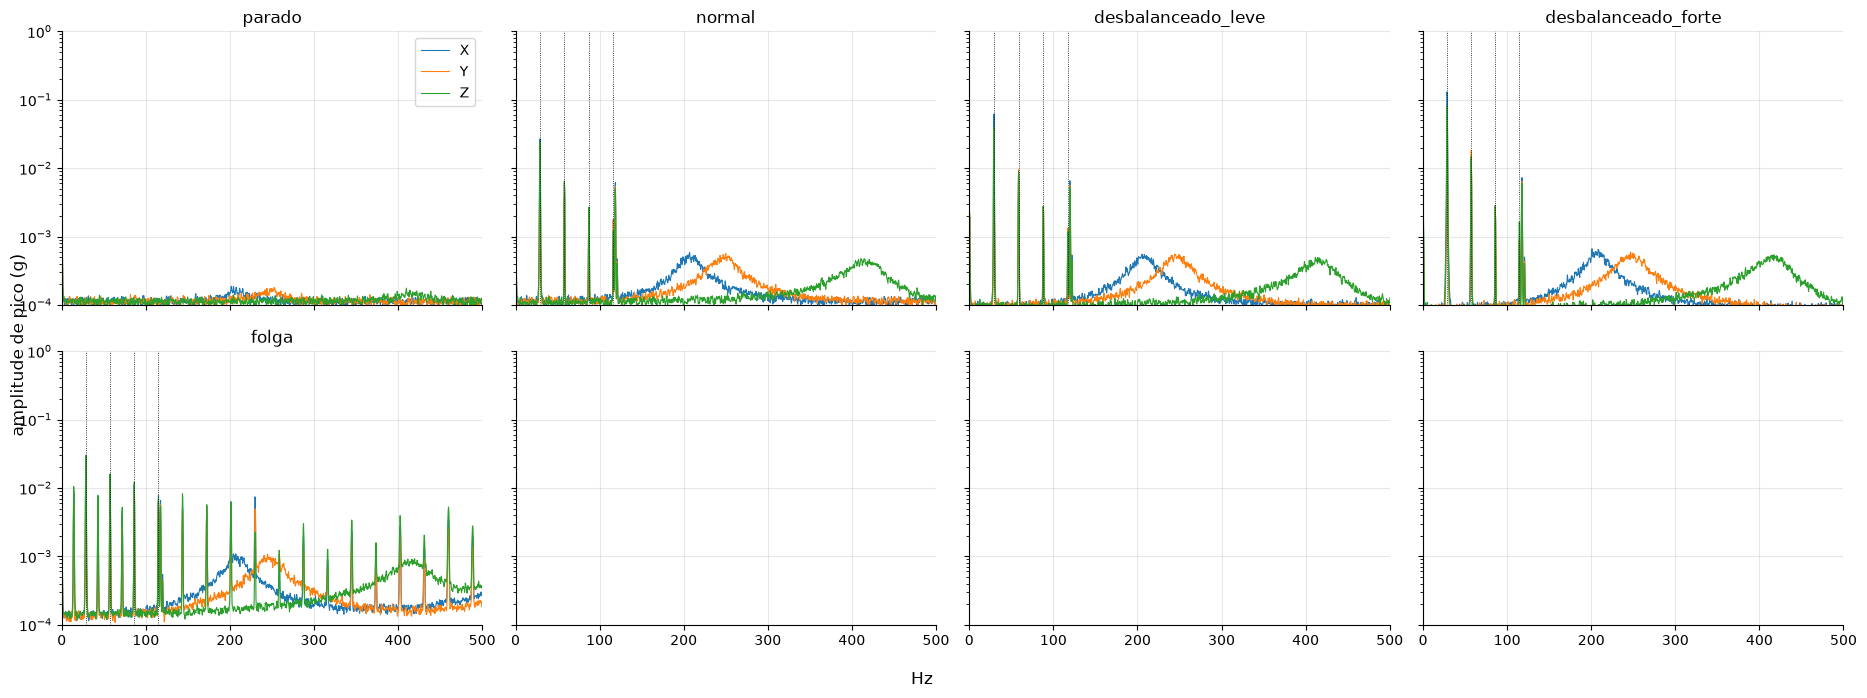

In [3]:
def get(label, speed="media", sess="1"):
    return next(r for r in recs if r.label == label and r.speed == speed and r.session == sess)

fig, axs = plt.subplots(2, 4, figsize=(19, 7), sharex=True, sharey=True)
for ax, label in zip(axs.ravel(), CLASSES):
    r = get(label); g = r.load(); fr = fr_of(r, g)
    f, P = signal.welch(g - g.mean(0), r.fs, nperseg=4096, axis=0, scaling="spectrum")
    for a, c in enumerate("xyz"):
        ax.semilogy(f, np.sqrt(2 * P[:, a]), color=COLORS[c], lw=.8, label=c.upper())
    if not np.isnan(fr):
        for k in (1, 2, 3, 4):
            ax.axvline(k * fr, color="k", ls=":", lw=.6)
    ax.set_title(label); ax.set_xlim(0, 500); ax.set_ylim(1e-4, 1)
axs[0, 0].legend(); fig.supxlabel("Hz"); fig.supylabel("amplitude de pico (g)")
plt.tight_layout(); plt.show()

**Leitura física** (confira nos gráficos): *desbalanceado* → 1× radial (X e Z) bem acima do normal; *desalinhado* → 1× e 2×
no eixo **axial** (Y) e 2× radial (só aparece se houver essa classe nos dados); *folga* → muitos harmônicos, **0,5× e 1,5×**
(sub-harmônicos) e piso de ruído maior; *parado* → só ruído e a gravidade.

In [4]:
# Tabela de amplitudes (mg pico) nas ordens-chave, por classe e eixo — velocidade média, sessão 1
rows = []
for label in CLASSES:
    r = get(label); g = r.load(); fr = fr_of(r, g)
    if np.isnan(fr): continue
    W, _ = vf.make_windows(g, r.fs)
    F = vf.window_features(W, r.fs, fr)
    row = {"classe": label}
    for k in (0.5, 1, 2, 3):
        for ax in "xyz":
            row[f"{k:g}× {ax.upper()}"] = 1000 * 10 ** np.median(F[f"o{k:g}_{ax}"])
    rows.append(row)
display(pd.DataFrame(rows).set_index("classe").round(0).astype(int).style.background_gradient(axis=0, cmap="Reds"))

,0.5× X,0.5× Y,0.5× Z,1× X,1× Y,1× Z,2× X,2× Y,2× Z,3× X,3× Y,3× Z
classe,,,,,,,,,,,,
normal,0,0,0,30,16,27,6,6,6,3,3,3
desbalanceado_leve,0,0,0,58,25,37,8,9,9,3,3,3
desbalanceado_forte,0,0,0,137,50,84,13,17,14,3,3,3
folga,6,4,8,28,16,28,17,14,17,10,8,11


## 3. Features

Para cada gravação: (1) descarta as pontas (`trim_s`) e janelas que cruzam pacotes perdidos; (2) **estima a rotação** pelo
espectro (o rpm não é gravado; num sistema real use o rpm conhecido); (3) fatia em janelas de 2 s; (4) extrai ~80 features
(`vibfeatures.py`). O mesmo módulo servirá para classificar ao vivo.

In [5]:
t0 = time.time()
df = vf.build_dataset(recs, bands=SPEED_BANDS_HZ, verbose=True)
FEATS = vf.feature_columns(df)
y = df.classe.values; groups = df.sessao.values
print(f"{df.shape[0]} janelas × {len(FEATS)} features em {time.time() - t0:.0f} s")
display(df.groupby("classe").size().reindex(CLASSES).to_frame("janelas").T)

  20/75 gravações


  40/75 gravações


  60/75 gravações


4125 janelas × 78 features em 8 s


classe,parado,normal,desbalanceado_leve,desbalanceado_forte,folga
janelas,825,825,825,825,825


### 3.1 A estimativa de rotação é confiável?

In [6]:
truth = {r.id: r.meta["sim"]["f_rotor_hz"] * r.meta["fs"] / r.meta["sim"]["fs_true"] for r in recs if "sim" in r.meta}   # Hz aparentes no eixo nominal
if truth:
    cmp = pd.DataFrame({"com faixa esperada": df.groupby("id").fr_est.first(),
                        "cega (sem faixa)": {r.id: vf.estimate_fr(r.load(), r.fs) for r in recs},
                        "verdade": pd.Series(truth)}).join(inv.set_index("id")[["classe", "velocidade"]])
    run = cmp[cmp.classe != "parado"]
    for col in ("com faixa esperada", "cega (sem faixa)"):
        err = 100 * (run[col] / run["verdade"] - 1)
        print(f"{col:20s}: |erro| < 2 % em {(err.abs() < 2).mean() * 100:.0f} % das gravações que giram; "
              f"'parado' reconhecido como parado em {cmp[cmp.classe == 'parado'][col].isna().mean() * 100:.0f} %")
    bad = run[(100 * (run["cega (sem faixa)"] / run["verdade"] - 1)).abs() >= 2].copy()
    bad["erro cega (%)"] = 100 * (bad["cega (sem faixa)"] / bad["verdade"] - 1)
    display(bad[["classe", "velocidade", "verdade", "cega (sem faixa)", "erro cega (%)"]].round(1))
else:
    print("Sem verdade-terreno (dados reais): compare com o rpm conhecido do motor.")

com faixa esperada  : |erro| < 2 % em 100 % das gravações que giram; 'parado' reconhecido como parado em 100 %
cega (sem faixa)    : |erro| < 2 % em 97 % das gravações que giram; 'parado' reconhecido como parado em 100 %


,classe,velocidade,verdade,cega (sem faixa),erro cega (%)
folga_alta_s2_20261101-021858,folga,alta,45.0,22.5,-50.0
folga_media_s5_20261101-021942,folga,media,29.2,14.6,-50.0


**Lição:** sem informação sobre a velocidade, a rotação é **ambígua** (um espectro com picos em c, 2c, 3c não diz se c é
0,5×, 1× ou 2×). Os erros acima (quando aparecem) são justamente os casos em que um harmônico ou sub-harmônico domina o 1×: a folga (0,5× forte) e o desalinhamento (2× forte). Por isso o pipeline
recebe a **faixa esperada de rotação** de cada velocidade (o setpoint do motor); a estimativa cega fica só como alternativa.

## 4. Comparação de algoritmos — leave-one-session-out

Para cada sessão: treina nas outras e testa nela. Reporta média ± desvio entre sessões (o desvio mostra o quanto o resultado
depende da montagem). Só os modelos que treinam em segundos entram; o critério de decisão está no topo.

In [7]:
X = df[FEATS].values
logo = LeaveOneGroupOut()
folds = list(logo.split(X, y, groups))
models = {
    "Regressão logística": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=10, gamma="scale")),
    "Rede neural (MLP)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, max_iter=400, early_stopping=True, random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                                        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
                                                        l2_regularization=1.0, random_state=SEED),
}
from sklearn.base import clone
res, oof = [], {}
for name, m in models.items():
    pred = np.empty(len(y), dtype=object); f1s, bas, t_fit = [], [], []
    for tr, te in folds:
        mm = clone(m); t = time.time(); mm.fit(X[tr], y[tr]); t_fit.append(time.time() - t)
        pred[te] = mm.predict(X[te])
        f1s.append(f1_score(y[te], pred[te], average="macro")); bas.append(balanced_accuracy_score(y[te], pred[te]))
    t = time.time(); mm.predict(X[folds[0][1]]); lat = (time.time() - t) / len(folds[0][1]) * 1000
    oof[name] = pred
    res.append({"modelo": name, "F1-macro": np.mean(f1s), "± desvio": np.std(f1s), "acc. balanceada": np.mean(bas),
                "pior sessão (F1)": np.min(f1s), "treino (s)": np.mean(t_fit), "predição (ms/janela)": lat})
    print(f"{name:22s} F1-macro {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
res = pd.DataFrame(res).set_index("modelo").sort_values("F1-macro", ascending=False)
display(res.round(3))

Regressão logística    F1-macro 0.903 ± 0.095


SVM (RBF)              F1-macro 0.918 ± 0.077


Rede neural (MLP)      F1-macro 0.909 ± 0.104


Random Forest          F1-macro 0.918 ± 0.108


Extra Trees            F1-macro 0.882 ± 0.139


Gradient Boosting      F1-macro 0.895 ± 0.092


,F1-macro,± desvio,acc. balanceada,pior sessão (F1),treino (s),predição (ms/janela)
modelo,,,,,,
Random Forest,0.918,0.108,0.923,0.709,1.101,0.115
SVM (RBF),0.918,0.077,0.922,0.790,0.060,0.045
Rede neural (MLP),0.909,0.104,0.919,0.712,0.411,0.002
Regressão logística,0.903,0.095,0.913,0.760,0.145,0.001
Gradient Boosting,0.895,0.092,0.903,0.753,1.241,0.025
Extra Trees,0.882,0.139,0.894,0.620,0.601,0.112


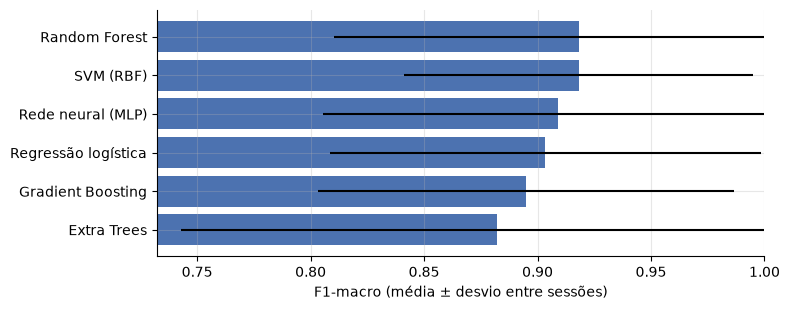

Melhor: Random Forest. Random Forest está DENTRO de 1 desvio do melhor → pela regra, o escolhido é Random Forest.


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(res.index[::-1], res["F1-macro"][::-1], xerr=res["± desvio"][::-1], color="#4c72b0")
ax.set_xlim(max(0, res["F1-macro"].min() - .15), 1.0); ax.set_xlabel("F1-macro (média ± desvio entre sessões)")
plt.tight_layout(); plt.show()
best = res.index[0]; rf = res.loc["Random Forest"]
within = rf["F1-macro"] >= res["F1-macro"].iloc[0] - res["± desvio"].iloc[0]
print(f"Melhor: {best}. Random Forest está {'DENTRO' if within else 'FORA'} de 1 desvio do melhor "
      f"→ pela regra, o escolhido é {'Random Forest' if within else best}.")
CHOSEN = "Random Forest" if within else best

**Leitura.** Os seis algoritmos ficam entre 0,88 e 0,92 de F1-macro; a diferença entre eles é menor que o desvio entre sessões
(0,08 a 0,14). **Random Forest e SVM-RBF empatam em 0,918**; o SVM tem menos variação entre sessões (± 0,077 contra ± 0,108) e
melhor pior-sessão (0,79 contra 0,71). Pela regra fixada antes dos resultados, fica o **Random Forest** (mais simples de
explicar e de manter, sem normalização, com importância de features). Se os dados reais repetirem esse padrão, o SVM é a
alternativa natural. O que decide o desempenho aqui é a **qualidade das features e a validação**, não a escolha do algoritmo.

## 5. Modelo escolhido: onde acerta e onde erra

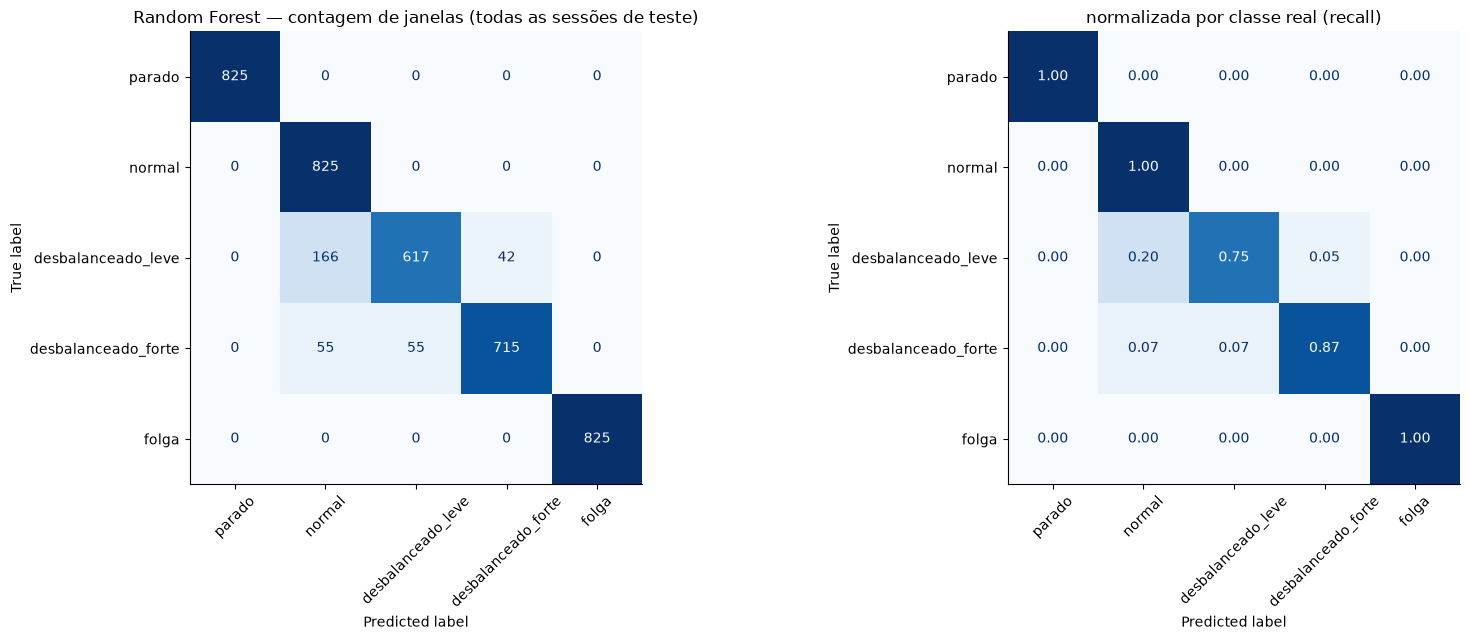

In [9]:
pred = oof[CHOSEN]
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=CLASSES, xticks_rotation=45, ax=axs[0], colorbar=False, cmap="Blues")
axs[0].set_title(f"{CHOSEN} — contagem de janelas (todas as sessões de teste)"); axs[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y, pred, labels=CLASSES, normalize="true", xticks_rotation=45, ax=axs[1],
                                        colorbar=False, cmap="Blues", values_format=".2f")
axs[1].set_title("normalizada por classe real (recall)"); axs[1].grid(False)
plt.tight_layout(); plt.show()

In [10]:
# Recall por classe × velocidade: onde está a dificuldade?
d = pd.DataFrame({"classe": y, "velocidade": df.velocidade.values, "ok": pred == y})
tab = d.groupby(["classe", "velocidade"]).ok.mean().unstack().reindex(CLASSES)
tab = tab[[c for c in ["baixa", "media", "alta"] if c in tab.columns]]
display(tab.style.background_gradient(cmap="RdYlGn", vmin=.5, vmax=1).format("{:.2f}"))

velocidade,baixa,media,alta
classe,,,
parado,1.00,1.00,1.00
normal,1.00,1.00,1.00
desbalanceado_leve,0.50,0.76,0.99
desbalanceado_forte,0.80,0.80,1.00
folga,1.00,1.00,1.00


**Como ler:** erros concentrados em *normal ↔ desbalanceado_leve* em baixa rotação são **físicos**, não do modelo: a
amplitude do desbalanço cai com ≈ f⁴ abaixo da ressonância, então um desbalanço leve a 1200 rpm fica abaixo da variação natural
do 1× de um motor saudável. Nenhum algoritmo resolve isso; só mais sensibilidade (sensor mais perto, melhor fixação) ou uma
referência de fase.

## 6. Da janela à decisão: suavização e "não sei"

O modelo classifica uma janela de 2 s a cada 1 s. Falhas são persistentes, então a decisão final deve usar várias janelas:
**média causal das probabilidades das últimas N janelas** (causal = só usa o passado, como ao vivo). Quanto maior N, mais
estável e mais lenta a resposta.

In [11]:
rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
cls = None; P = None
for tr, te in folds:
    mm = clone(rf_model).fit(X[tr], y[tr])
    if P is None:
        cls = mm.classes_; P = np.zeros((len(y), len(cls)))
    P[te] = mm.predict_proba(X[te])

def causal_mean(P, ids, N):
    out = np.empty_like(P)
    for i in np.unique(ids):
        m = ids == i; c = np.cumsum(P[m], axis=0)
        s = c.copy(); s[N:] -= c[:-N]
        out[m] = s / np.minimum(np.arange(1, m.sum() + 1), N)[:, None]
    return out

hop = (df.t0.groupby(df.id).diff().dropna().median())
Ns = [1, 3, 5, 9, 15]
rows = []
for N in Ns:
    Ps = causal_mean(P, df.id.values, N)
    pr = cls[Ps.argmax(1)]
    rows.append({"N janelas": N, "atraso p/ decidir (s)": 2 + (N - 1) * hop,
                 "F1-macro": f1_score(y, pr, average="macro"), "acc. balanceada": balanced_accuracy_score(y, pr)})
sm = pd.DataFrame(rows).set_index("N janelas")
display(sm.round(3))

,atraso p/ decidir (s),F1-macro,acc. balanceada
N janelas,,,
1,2.0,0.922,0.923
3,4.0,0.920,0.921
5,6.0,0.921,0.922
9,10.0,0.924,0.925
15,16.0,0.925,0.926


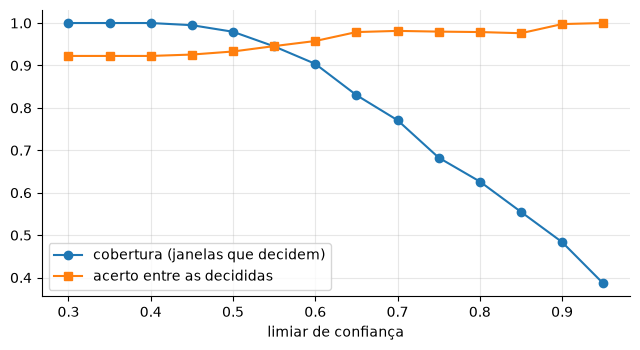

In [12]:
# Limiar de confiança: abaixo dele a resposta é "incerto". Cobertura x acerto (N = 5)
Ps = causal_mean(P, df.id.values, 5); conf = Ps.max(1); pr = cls[Ps.argmax(1)]
ths = np.linspace(0.3, 0.95, 14)
cov = [(conf >= t).mean() for t in ths]; acc = [(pr[conf >= t] == y[conf >= t]).mean() for t in ths]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(ths, cov, "o-", label="cobertura (janelas que decidem)"); ax.plot(ths, acc, "s-", label="acerto entre as decididas")
ax.set_xlabel("limiar de confiança"); ax.legend(); plt.tight_layout(); plt.show()

**Leitura.** Suavizar **não ajuda** (F1 0,922 com N = 1 contra 0,925 com N = 15): os erros não são ruído de janela, são
**sistemáticos por sessão e por classe** (peso leve parecido com normal em baixa rotação). Janelas vizinhas erram juntas, então
a média não corrige. Suavização serve para estabilizar o alarme (menos piscadas) e custa latência (16 s para N = 15). O
limiar de confiança é a ferramenta útil: ele troca cobertura por acerto e produz o "incerto" que um operador espera.

## 7. Robustez — o que quebra o modelo?

Quatro perguntas práticas: depende de uma velocidade específica? o resultado vem de usar `fr` como atalho? qual família de
features carrega o diagnóstico? e **quantas remontagens do sensor (sessões) são necessárias** na coleta real?

In [13]:
def loso_f1(cols, model=None, folds_=None, Xmat=None):
    model = model or rf_model
    Xm = df[cols].values if Xmat is None else Xmat
    f1s = []
    for tr, te in (folds_ or folds):
        mm = clone(model).fit(Xm[tr], y[tr]); f1s.append(f1_score(y[te], mm.predict(Xm[te]), average="macro"))
    return np.mean(f1s), np.std(f1s)

# (a) generalizar para uma velocidade nunca vista (treino nas outras duas, em todas as sessões)
spd = df.velocidade.values
rows = []
for s in sorted(set(spd)):
    tr, te = np.flatnonzero(spd != s), np.flatnonzero(spd == s)
    mm = clone(rf_model).fit(X[tr], y[tr]); p = mm.predict(X[te])
    rows.append({"velocidade excluída": s, "F1-macro": f1_score(y[te], p, average="macro"), "acc. balanceada": balanced_accuracy_score(y[te], p)})
display(pd.DataFrame(rows).set_index("velocidade excluída").round(3))

,F1-macro,acc. balanceada
velocidade excluída,,
alta,0.625,0.680
baixa,0.484,0.525
media,0.671,0.696


In [14]:
# (b) sem a feature `fr` (rotação): o modelo não pode usar a velocidade como atalho
base = loso_f1(FEATS); nofr = loso_f1(vf.feature_columns(df, use_fr=False))
print(f"com fr: {base[0]:.3f} ± {base[1]:.3f}   sem fr: {nofr[0]:.3f} ± {nofr[1]:.3f}")

# (c) ablação por família de features (LOSO, sem a família)
fam = {
    "tempo (rms/crest/curtose)": [c for c in FEATS if c.split("_")[0] in ("rms", "crest", "kurt")],
    "ordens e razões": [c for c in FEATS if c[0] in "or" and c.split("_")[0][1:].replace(".", "").isdigit()],
    "bandas e forma": [c for c in FEATS if c.startswith(("b", "centroid", "hf"))],
    "axial/radial": [c for c in FEATS if c.startswith("ax_rad")],
}
rows = []
for name, cols in fam.items():
    keep = [c for c in FEATS if c not in cols]
    m_, s_ = loso_f1(keep)
    rows.append({"removida": name, "n features": len(cols), "F1-macro": m_, "queda vs. tudo": base[0] - m_})
ablation = pd.DataFrame(rows).set_index("removida")
display(ablation.round(3))

com fr: 0.918 ± 0.108   sem fr: 0.898 ± 0.127


,n features,F1-macro,queda vs. tudo
removida,,,
tempo (rms/crest/curtose),9,0.908,0.011
ordens e razões,42,0.885,0.033
bandas e forma,24,0.920,-0.001
axial/radial,2,0.919,-0.001


In [15]:
# (d) ruído extra no sensor: treina limpo x treina com augmentation (janelas com 0, 5, 15 e 30 mg extras misturadas)
levels = (0, 5, 15, 30)
Xl = {0: X}
for extra_mg in levels[1:]:
    Xl[extra_mg] = vf.build_dataset(recs, extra_noise_g=extra_mg / 1000, bands=SPEED_BANDS_HZ)[FEATS].values
res_n = {l: {"limpo": [], "aug": []} for l in levels}
for tr, te in folds:
    m_clean = clone(rf_model).fit(X[tr], y[tr])
    m_aug = clone(rf_model).fit(np.vstack([Xl[l][tr] for l in levels]), np.concatenate([y[tr]] * len(levels)))
    for l in levels:
        res_n[l]["limpo"].append(f1_score(y[te], m_clean.predict(Xl[l][te]), average="macro"))
        res_n[l]["aug"].append(f1_score(y[te], m_aug.predict(Xl[l][te]), average="macro"))
noise_tab = pd.DataFrame({l: {"F1 treino limpo": np.mean(v["limpo"]), "F1 com augmentation": np.mean(v["aug"]),
                              "± (aug.)": np.std(v["aug"])} for l, v in res_n.items()}).T
noise_tab.index.name = "ruído extra (mg RMS)"
display(noise_tab.round(3))

,F1 treino limpo,F1 com augmentation,± (aug.)
ruído extra (mg RMS),,,
0,0.918,0.897,0.142
5,0.844,0.893,0.141
15,0.067,0.881,0.141
30,0.067,0.883,0.147


,F1-macro,± desvio
sessões no treino,,
1,0.802,0.116
2,0.868,0.099
3,0.893,0.108
4,0.909,0.105


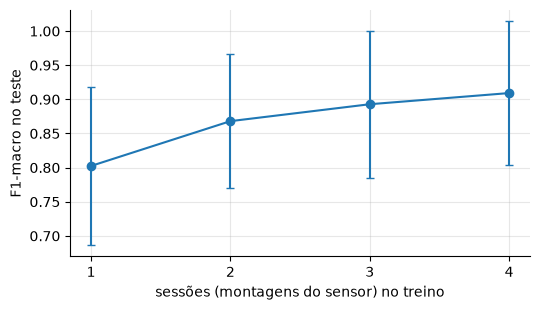

In [16]:
# (e) curva de aprendizado em SESSÕES: quantas montagens distintas o treino precisa ter?
import itertools
sess = sorted(set(groups)); rows = []
for k in range(1, len(sess)):
    f1s = []
    for te_s in sess:
        others = [s for s in sess if s != te_s]
        for tr_s in itertools.combinations(others, k):
            tr = np.flatnonzero(np.isin(groups, tr_s)); te = np.flatnonzero(groups == te_s)
            mm = clone(rf_model).set_params(n_estimators=120).fit(X[tr], y[tr])
            f1s.append(f1_score(y[te], mm.predict(X[te]), average="macro"))
    rows.append({"sessões no treino": k, "F1-macro": np.mean(f1s), "± desvio": np.std(f1s)})
lc = pd.DataFrame(rows).set_index("sessões no treino")
display(lc.round(3))
fig, ax = plt.subplots(figsize=(5.5, 3.2)); ax.errorbar(lc.index, lc["F1-macro"], lc["± desvio"], marker="o", capsize=3)
ax.set_xlabel("sessões (montagens do sensor) no treino"); ax.set_ylabel("F1-macro no teste"); ax.set_xticks(lc.index)
plt.tight_layout(); plt.show()

**Leitura da seção 7.**

* **Velocidade nunca vista é o ponto mais fraco** (F1 de 0,48 a 0,67): a amplitude da falha cresce com ≈ f⁴ e as classes de peso
  mudam de nível com a rotação, então o modelo **não extrapola**. Treine com todas as velocidades que vai usar.
* **Ruído:** treinado só com dados limpos, o modelo vai de 0,92 (limpo) para 0,84 (+5 mg) e **colapsa para uma única classe**
  com +15 mg (F1 0,067). Com *augmentation* (janelas com 0, 5, 15 e 30 mg misturadas no treino) fica em 0,88–0,90 em todos os
  níveis, ao custo de ~0,02 no caso limpo. Use augmentation, ou features relativas ao piso de ruído.
* **`fr` como atalho:** sem a rotação como feature o F1 vai de 0,918 para 0,898, ou seja, ela ajuda um pouco mas o modelo não
  depende dela.
* **Ablação por família:** tirar *ordens e razões* custa 0,033 (a mais importante); *tempo* 0,011; *bandas* e *axial/radial*
  não custam nada (redundantes).
* **Curva de aprendizado:** 0,80 com 1 sessão no treino, 0,87 com 2, 0,89 com 3, 0,91 com 4, e ainda subindo. **Quantas
  montagens distintas o treino vê importa mais que quantos minutos de gravação por sessão.** Na coleta real, planeje **no mínimo
  4 a 5 sessões** com o sensor desmontado e remontado.

## 8. Anomalia e falhas inéditas

Na prática, o classificador só conhece as falhas que você gravou. Duas camadas de proteção:

1. **Detector de anomalia** treinado **só com "normal"** (Isolation Forest): dá um escore de "o quão estranho é esta janela".
2. **Confiança do classificador** para uma falha *nunca vista*: se ele nunca viu a classe X, a probabilidade máxima deve cair.

In [17]:
# (1) AUROC "normal vs. cada falha" com Isolation Forest treinado só em 'normal' das sessões de treino
rows = []
for tr, te in folds:
    trn = tr[y[tr] == "normal"]
    iso = make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=SEED)).fit(X[trn])
    score = -iso.decision_function(X[te])
    for c in CLASSES:
        if c in ("normal", "parado"): continue
        m = np.isin(y[te], ["normal", c])
        rows.append({"classe": c, "AUROC": roc_auc_score(y[te][m] == c, score[m])})
display(pd.DataFrame(rows).groupby("classe").AUROC.agg(["mean", "std"]).reindex([c for c in CLASSES if c not in ("normal", "parado")]).round(3))

,mean,std
classe,,
desbalanceado_leve,0.759,0.121
desbalanceado_forte,0.906,0.079
folga,1.000,0.000


In [18]:
# (2) Falha inédita: treina SEM a classe X; ela é separável das conhecidas pela baixa confiança (1 - p_max)?
rows = []
faults = [c for c in CLASSES if c not in ("normal", "parado")]
small = clone(rf_model).set_params(n_estimators=150)
for held in faults:
    aucs = []
    for tr, te in folds:
        tr2 = tr[y[tr] != held]
        mm = clone(small).fit(X[tr2], y[tr2])
        known = np.isin(y[te], [c for c in CLASSES if c != held])
        score = 1 - mm.predict_proba(X[te]).max(1)
        aucs.append(roc_auc_score(y[te] == held, score))
    rows.append({"classe inédita": held, "AUROC (inédita vs. conhecidas)": np.mean(aucs), "± desvio": np.std(aucs)})
display(pd.DataFrame(rows).set_index("classe inédita").round(3))

,AUROC (inédita vs. conhecidas),± desvio
classe inédita,,
desbalanceado_leve,0.925,0.089
desbalanceado_forte,0.540,0.050
folga,0.974,0.029


**Leitura da seção 8.** O detector treinado só com "normal" acha a folga sempre (AUROC 1,00) e o peso grande bem (0,91), mas o peso
leve só moderadamente (0,76): ele é parecido com um motor saudável de verdade. Para uma falha **inédita**, a baixa confiança do
classificador denuncia a folga (0,97) e o peso leve (0,93) quando elas faltam no treino, mas **não** o peso grande (0,54),
porque ele é confundido com o "leve", que é da mesma família. Vale como alarme de "algo mudou", não como diagnóstico.

**Leitura:** AUROC ≈ 0,5 = nenhuma proteção; ≈ 1 = detecta sempre. Falhas que *parecem* uma conhecida (desbalanço forte sem a
classe "leve") são confundidas com ela; as de assinatura própria (folga) tendem a ser sinalizadas como estranhas.
Por isso o desenho final usa as duas camadas: **anomalia** para "algo mudou" e **classificador** para "o que é".

## 9. O que o modelo usa para decidir

,queda do F1,± desvio
bandas absolutas,0.119,0.017
tempo: rms / crest / curtose,0.113,0.034
razões entre ordens (÷ 1×),0.091,0.039
amplitude em 2×,0.013,0.017
amplitude em 1×,0.012,0.019
axial / radial,0.012,0.027
amplitude em 4×,0.005,0.007
amplitude em 2.5×,0.001,0.001
amplitude em 8×,0.001,0.005
amplitude em 7×,0.000,0.001


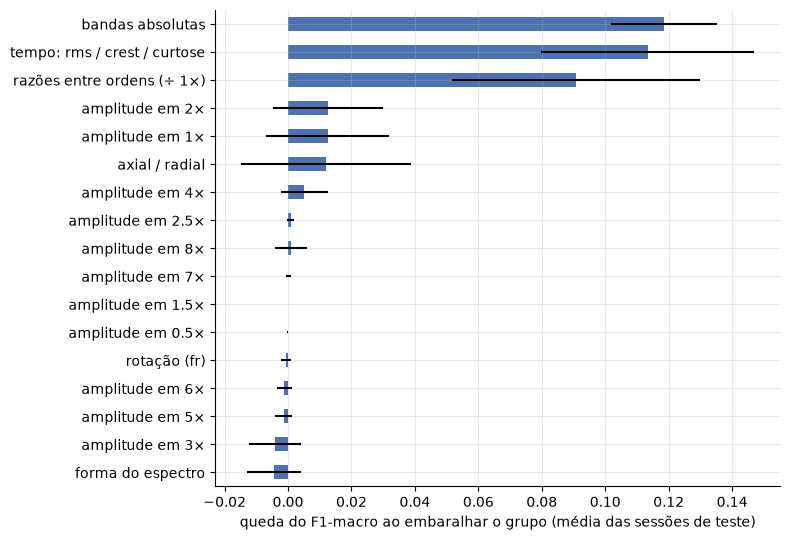

In [19]:
# Importância por GRUPO físico. Embaralhar uma feature isolada não muda nada (elas são redundantes entre si),
# então embaralha-se o grupo inteiro, de uma vez, no teste de cada sessão, e mede-se a queda do F1-macro.
def group_of(c):
    if c == "fr": return "rotação (fr)"
    if c.startswith(("rms", "crest", "kurt")): return "tempo: rms / crest / curtose"
    if c.startswith("ax_rad"): return "axial / radial"
    if c.startswith(("centroid", "hf")): return "forma do espectro"
    if c.startswith("b"): return "bandas absolutas"
    if c[0] == "r": return "razões entre ordens (÷ 1×)"
    if c[0] == "o": return "amplitude em " + c.split("_")[0][1:] + "×"
    return "outros"

fam_cols = {}
for i_, c in enumerate(FEATS):
    fam_cols.setdefault(group_of(c), []).append(i_)
rng = np.random.default_rng(SEED); drops = {k: [] for k in fam_cols}
for tr, te in folds:
    mm = clone(rf_model).fit(X[tr], y[tr]); base_f1 = f1_score(y[te], mm.predict(X[te]), average="macro")
    for name, idx in fam_cols.items():
        d = []
        for _ in range(3):
            Xp = X[te].copy(); Xp[:, idx] = Xp[rng.permutation(len(te))][:, idx]
            d.append(base_f1 - f1_score(y[te], mm.predict(Xp), average="macro"))
        drops[name].append(np.mean(d))
imp = pd.DataFrame({"queda do F1": {k: np.mean(v) for k, v in drops.items()},
                    "± desvio": {k: np.std(v) for k, v in drops.items()}}).sort_values("queda do F1", ascending=False)
display(imp.round(3))
fig, ax = plt.subplots(figsize=(8, 5.5)); imp["queda do F1"][::-1].plot.barh(ax=ax, xerr=imp["± desvio"][::-1], color="#4c72b0")
ax.set_xlabel("queda do F1-macro ao embaralhar o grupo (média das sessões de teste)"); plt.tight_layout(); plt.show()

**Leitura.** Quase tudo vem de três grupos: **bandas absolutas** (queda de 0,12 no F1 ao embaralhar), **tempo** (rms/crest/curtose, 0,11)
e **razões entre ordens** (0,09). As amplitudes individuais em 1× e 2× pesam pouco (≈ 0,01) *porque o resto da informação as
substitui*: o desbalanceamento é basicamente energia extra em 1×, que aparece também no rms e nas bandas de 10–50 Hz. As
**razões** (0,5×/1×, 2×/1×, 3×/1×) são o que separa a **folga** das outras classes, e sem elas o F1 cai (tabela de ablação).
Consequência prática: o modelo se apoia em **níveis absolutos**, então é sensível a ganho e ruído do sensor, o que explica o
colapso com ruído extra da seção 7 e por que o *augmentation* de ruído resolveu. Os grupos são redundantes entre si, por isso
embaralhar uma feature isolada não muda nada e o gráfico acima é por grupo.

## 10. Modelo final

Treinado com **todas** as sessões e salvo em `models/` junto com as features e as classes. O uso ao vivo será:
janela de 2 s → `vibfeatures.window_features` → `predict_proba` → média das últimas N → limiar de confiança.

In [20]:
final = clone(rf_model).fit(X, y)
final.set_params(n_jobs=1)           # inferência de 1 janela: sem overhead de paralelismo
Path("models").mkdir(exist_ok=True)
joblib.dump({"model": final, "features": FEATS, "classes": list(final.classes_), "fs": recs[0].fs,
             "win_s": vf.WIN_S, "trained_on": SOURCE or "todos"}, "models/rf_falhas.joblib")

# custo de uma decisão: features + modelo, 1 janela
r = get("folga"); g = r.load(); fr = fr_of(r, g); W, _ = vf.make_windows(g, r.fs)
t = time.time()
for _ in range(20):
    F = vf.window_features(W[:1], r.fs, fr); xrow = np.array([[F[c][0] for c in FEATS]]); pr = final.predict_proba(xrow)
ms = (time.time() - t) / 20 * 1000
print(f"1 janela de 2 s: features + modelo = {ms:.1f} ms ({ms / 1000 / 2 * 100:.2f} % do tempo real)  ·  arquivo: models/rf_falhas.joblib")

1 janela de 2 s: features + modelo = 29.6 ms (1.48 % do tempo real)  ·  arquivo: models/rf_falhas.joblib


## 11. Conclusões

### Resultado principal

Com 75 gravações simuladas (5 classes × 3 velocidades × 5 sessões, 4125 janelas de 2 s) e **validação deixando uma sessão de
fora**, o classificador chega a **F1-macro 0,92 ± 0,11** (acurácia balanceada 0,92). **Parado, normal e folga são reconhecidos em
100 % das janelas**; todo o erro está na **graduação do peso no eixo**: o peso leve é confundido com "normal" em 20 % das
janelas (recall 0,75; em baixa rotação cai para 0,50) e o peso grande com leve ou normal em 13 % (recall 0,87). Uma janela de 2 s
é classificada em ~30 ms (1,5 % do tempo real), com treino de ~1 s.

### Algoritmo e estratégia (resposta à pergunta de projeto)

* **Algoritmo: Random Forest** sobre ~80 features espectrais em ordens da rotação. Empata estatisticamente com o SVM-RBF (0,918) e
  fica acima de MLP, regressão logística, Gradient Boosting e Extra Trees (0,88–0,91); a escolha foi feita pela regra definida
  antes dos resultados.
* **Estratégia que de fato importa:** (1) **validar por sessão**, nunca por janela; (2) **features em ordens**, com a rotação
  informada (faixa esperada); (3) **treinar com todas as velocidades e com várias remontagens do sensor**; (4) **augmentation de
  ruído**; (5) decisão com **limiar de confiança**, não só `argmax`.
* **Não** vale a pena aqui: rede profunda sobre o sinal bruto; suavizar mais de 3 janelas (não melhora o F1).

### Limitações (declare no artigo)

1. **Os dados são simulados**, gerados por um modelo físico que compartilha as premissas das features (1×, 2×, sub-harmônicos).
   Isto valida o **método e o pipeline**, não o desempenho num motor real, que será pior (ressonâncias reais, alimentação ruidosa,
   falhas menos limpas). O simulador **não foi calibrado** com dados reais.
2. Só 5 sessões: o desvio entre sessões é grande (± 0,11) e a curva de aprendizado ainda não saturou.
3. A **rotação precisa ser informada**; estimada às cegas só pelo espectro, ela é ambígua (errou −50 % em 2 gravações de folga, onde
   o 0,5× é forte).
4. Só duas falhas físicas (peso e folga) mais o desalinhamento opcional; rolamentos, desgaste e falhas elétricas ficaram fora.
5. O modelo depende de níveis absolutos: mudar o sensor, o ganho ou a fixação sem retreinar pode quebrá-lo.

### Próximos passos

1. Montar o motor, coletar com o procedimento do coletor (≥ 4–5 sessões, 3 velocidades, 2–3 tamanhos de peso medidos, `normal` em
   toda sessão) e rodar este mesmo notebook trocando `DATA_DIR`, `SOURCE` e `SPEED_BANDS_HZ`.
2. Comparar os resultados reais com os simulados: a diferença mede o quanto o simulador superestima.
3. Implementar a classificação ao vivo no Windows (janela de 2 s → `vibfeatures` → `models/rf_falhas.joblib` → média curta →
   limiar de confiança), com o detector de anomalia como segundo alarme.